# Comparing random forests and the multi-output meta estimator: scikit-learn vs Moxie

**Reference example:** `../scikit-learn/examples/ensemble/plot_random_forest_regression_multioutput.py` at scikit-learn
`4358542a1bd39af2e7e1cbace8b9fed067473c5b`
([rendered gallery page](https://scikit-learn.org/dev/auto_examples/ensemble/plot_random_forest_regression_multioutput.html)).

**Scenario:** one noisy feature drives two targets on a circle. `MultiOutputRegressor` fits one
`RandomForestRegressor(n_estimators=100, max_depth=30, random_state=0)` per target and is compared with a
natively multi-output `RandomForestRegressor(..., random_state=2)`; both are scored with uniform-average R2
and plotted.

**Adaptations**
- None to the data or the parameters: the example's synthetic data (`np.random.RandomState(1)`) and
  `train_test_split(..., random_state=4)` are generated in Python and shared with Mojo.
- Moxie forests take Float32 feature matrices and Float64 targets, so the wrapper is
  `MultiOutputRegressor[RandomForestRegressor, DType.float32, DType.float64]`. scikit-learn's forests also
  cast `X` to float32 internally, so both sides train on identical values.
- `plt.show()` is replaced by a small figure (dpi 80) next to Moxie's version.

**Determinism:** deterministic. Every forest has an integer `random_state`; scikit-learn clones the template
for each output, so both per-output forests use seed 0. Moxie's forests reproduce scikit-learn's bootstrap
and split draws for integer seeds, so predictions must match exactly.

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "notebooks/_support/moxie_nb.py").exists())
sys.path.insert(0, str(ROOT / "notebooks/_support"))
%load_ext moxie_nb
nb = moxie_nb.Session("multioutput/plot_random_forest_regression_multioutput")

## 1. scikit-learn (Python reference)

The official example code; only `plt.show()` is deferred to the side-by-side plot.

In [2]:
import matplotlib.pyplot as plt
import numpy as np

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.multioutput import MultiOutputRegressor

# Create a random dataset
rng = np.random.RandomState(1)
X = np.sort(200 * rng.rand(600, 1) - 100, axis=0)
y = np.array([np.pi * np.sin(X).ravel(), np.pi * np.cos(X).ravel()]).T
y += 0.5 - rng.rand(*y.shape)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, train_size=400, test_size=200, random_state=4
)

max_depth = 30
regr_multirf = MultiOutputRegressor(
    RandomForestRegressor(n_estimators=100, max_depth=max_depth, random_state=0)
)
regr_multirf.fit(X_train, y_train)

regr_rf = RandomForestRegressor(n_estimators=100, max_depth=max_depth, random_state=2)
regr_rf.fit(X_train, y_train)

# Predict on new data
y_multirf = regr_multirf.predict(X_test)
y_rf = regr_rf.predict(X_test)
sk_scores = np.array([regr_multirf.score(X_test, y_test), regr_rf.score(X_test, y_test)])
print("sklearn scores (Multi RF, RF):", sk_scores)
print("per-output estimators:", len(regr_multirf.estimators_), "n_features_in_:", regr_multirf.n_features_in_)
nb.share(X_train=X_train, y_train=y_train, X_test=X_test, y_test=y_test)

sklearn scores (Multi RF, RF): [0.84388463 0.84137589]
per-output estimators: 2 n_features_in_: 1


## 2. Moxie (native Mojo)

The same scenario through `moxie.multioutput.MultiOutputRegressor` and `moxie.ensemble.RandomForestRegressor`.
Python only supplies the arrays; fitting, prediction and scoring run in Mojo.

In [3]:
%%mojo rf_multioutput
from moxie.ensemble import RandomForestRegressor
from moxie.multioutput import MultiOutputRegressor
from moxie_nb_io import load, save, save_floats


def main() raises:
    var X_train = load[DType.float32]("X_train")
    var y_train = load("y_train")
    var X_test = load[DType.float32]("X_test")
    var y_test = load("y_test")

    var regr_multirf = MultiOutputRegressor[RandomForestRegressor, DType.float32, DType.float64](
        RandomForestRegressor(100, max_depth=30, random_state=0))
    _ = regr_multirf.fit(X_train, y_train)
    var regr_rf = RandomForestRegressor(100, max_depth=30, random_state=2)
    _ = regr_rf.fit(X_train, y_train)

    save("y_multirf", regr_multirf.predict(X_test))
    save("y_rf", regr_rf.predict(X_test))
    var scores = List[Float64]()
    scores.append(regr_multirf.score(X_test, y_test))
    scores.append(regr_rf.score(X_test, y_test))
    save_floats("scores", scores)
    print("moxie scores (Multi RF, RF):", scores[0], scores[1])
    print("per-output estimators:", len(regr_multirf.estimators_), "n_features_in_:", regr_multirf.n_features_in_.value())

moxie scores (Multi RF, RF): 0.8438846330802694 0.8413758920895975
per-output estimators: 2 n_features_in_: 1


## 3. Side by side and parity

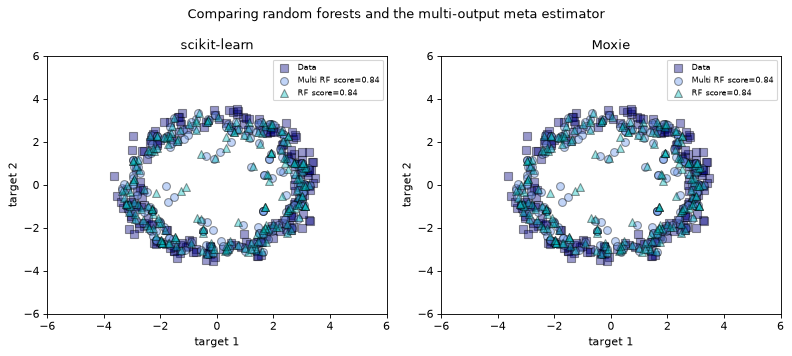

check,status,sklearn shape,moxie shape,max |diff|,max rel,tolerance,detail,tolerance reason
MultiOutputRegressor(RF).predict,PASS,"(200, 2)","(200, 2)",,,exact,0 mismatches,
RandomForestRegressor multi-output predict,PASS,"(200, 2)","(200, 2)",,,exact,0 mismatches,
"R2 scores (Multi RF, RF)",PASS,"(2,)","(2,)",0,0,"rtol=1e-12, atol=0",,identical predictions; R2 reductions sum in a different order than NumPy


In [4]:
mx = nb.results["rf_multioutput"]

def panel(ax, multi, single, scores, title):
    s, a = 50, 0.4
    ax.scatter(y_test[:, 0], y_test[:, 1], edgecolor="k", c="navy", s=s, marker="s", alpha=a, label="Data")
    ax.scatter(multi[:, 0], multi[:, 1], edgecolor="k", c="cornflowerblue", s=s, alpha=a,
               label="Multi RF score=%.2f" % scores[0])
    ax.scatter(single[:, 0], single[:, 1], edgecolor="k", c="c", s=s, marker="^", alpha=a,
               label="RF score=%.2f" % scores[1])
    ax.set_xlim([-6, 6]); ax.set_ylim([-6, 6])
    ax.set_xlabel("target 1"); ax.set_ylabel("target 2")
    ax.set_title(title); ax.legend(fontsize=7)

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), dpi=80)
panel(axes[0], y_multirf, y_rf, sk_scores, "scikit-learn")
panel(axes[1], mx["y_multirf"], mx["y_rf"], mx["scores"], "Moxie")
fig.suptitle("Comparing random forests and the multi-output meta estimator")
plt.tight_layout()
plt.show()

moxie_nb.side_by_side(sklearn=y_multirf[:5], moxie=mx["y_multirf"][:5])
nb.compare("MultiOutputRegressor(RF).predict", y_multirf, mx["y_multirf"], exact=True)
nb.compare("RandomForestRegressor multi-output predict", y_rf, mx["y_rf"], exact=True)
nb.compare("R2 scores (Multi RF, RF)", sk_scores, mx["scores"], rtol=1e-12, atol=0,
           reason="identical predictions; R2 reductions sum in a different order than NumPy")
nb.report()
nb.assert_parity()